# 10 - Density-Based Clustering: DBSCAN (and HDBSCAN)
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 3 - Model Engineering (Density-Based Clustering)

**Project stage:** 10 of 16 - builds on Notebook 07's preprocessed feature matrix

---

## 1. Objective

This notebook investigates DBSCAN, a fundamentally different clustering approach from K-Means (Notebook 08) and Hierarchical Clustering (Notebook 09): it does not require choosing K in advance, and it can explicitly label some bookings as noise rather than forcing every single booking into a cluster.

We will:
1. Explain how DBSCAN defines a cluster through local density, and what eps and min_samples control.
2. Use a k-distance graph to choose candidate eps values systematically, rather than by guesswork.
3. Run a systematic, evidence-based parameter search across multiple eps/min_samples combinations, on the full ~87,000-row dataset (unlike Notebook 09, DBSCAN's algorithm doesn't require the full O(n^2) distance matrix, so no sampling is needed here).
4. Report exactly what we find - including a genuine limitation this dataset exposes about density-based clustering in high-dimensional, mixed-type feature spaces.
5. Optionally test HDBSCAN (available natively in this environment's scikit-learn version), which adapts to varying density automatically instead of requiring one single global eps.

## 2. Business Context

**What is density-based clustering, conceptually?** Instead of measuring distance to a centroid (K-Means) or building a merge tree (Hierarchical), DBSCAN looks at local crowding. A booking is a core point if at least min_samples other bookings fall within distance eps of it. Bookings reachable through a chain of core points form one cluster. A booking that isn't close enough to enough neighbors to be part of any dense region is labeled noise (-1) - not forced into the nearest cluster regardless of fit.

**Why is this potentially valuable for a hotel?** Some bookings genuinely don't belong to any repeatable behavioral pattern - a one-off, unusual booking that doesn't resemble a meaningful group. DBSCAN is the one algorithm in this project that can say this booking doesn't fit any of our segments instead of squeezing it into the closest one. Whether that turns out to be a genuine strength or a limitation on this specific dataset is exactly what this notebook investigates with real evidence.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: DBSCAN, HDBSCAN, nearest-neighbor search for the k-distance
# graph, evaluation metrics, and PCA for visualization
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

# joblib: to save fitted models for reuse in later notebooks
import joblib

# os / time: file paths and timing
import os
import time


## 4. Configuration

In [2]:
RANDOM_STATE = 42

PREPROCESSED_FEATURES_PATH = "../data/processed/07_preprocessed_features.csv"

DBSCAN_GRID_RESULTS_PATH = "../reports/tables/10_dbscan_grid_results.csv"
DENSITY_MODELS_PATH = "../models/density_candidate_models.joblib"
DENSITY_LABELS_PATH = "../data/processed/10_density_candidate_labels.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs("../models", exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 150)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


## 5. Analysis / Implementation

### 5.1 Load the Preprocessed Feature Matrix

Unlike Notebook 09's hierarchical clustering, DBSCAN does not need the full pairwise distance matrix held in memory at once - it uses spatial indexing to search for neighbors efficiently. This means we can run it on the full, unsampled dataset.

In [3]:
X = pd.read_csv(PREPROCESSED_FEATURES_PATH)

print("Full preprocessed feature matrix shape:", X.shape)


Full preprocessed feature matrix shape: (86997, 40)


### 5.2 The k-Distance Graph - Choosing eps Systematically

**What is a k-distance graph?** For every booking, we compute the distance to its k-th nearest neighbor (where k = min_samples), then sort all of these distances from smallest to largest and plot them. The idea: in a dense region, a point's k-th nearest neighbor is close by (small distance); in a sparse region, it's far away (large distance). Where the sorted curve bends sharply upward - the knee - is a data-driven candidate for eps, since it marks a natural transition from typically-dense to typically-sparse.

In [4]:
K_FOR_DISTANCE_GRAPH = 10  # matches a min_samples value we test below

start_time = time.time()
nearest_neighbors = NearestNeighbors(n_neighbors=K_FOR_DISTANCE_GRAPH)
nearest_neighbors.fit(X)
neighbor_distances, neighbor_indices = nearest_neighbors.kneighbors(X)

# The distance to the k-th (furthest) neighbor for each point, sorted.
k_distances_sorted = np.sort(neighbor_distances[:, -1])

print(f"k-distance computation time: {time.time() - start_time:.1f} seconds")
print()
print("k-distance percentiles (k = 10):")
for percentile in [10, 25, 50, 75, 90, 95, 99]:
    print(f"  p{percentile}: {np.percentile(k_distances_sorted, percentile):.3f}")


k-distance computation time: 73.0 seconds

k-distance percentiles (k = 10):
  p10: 0.132
  p25: 0.259
  p50: 0.529
  p75: 1.033
  p90: 1.426
  p95: 1.635
  p99: 2.168


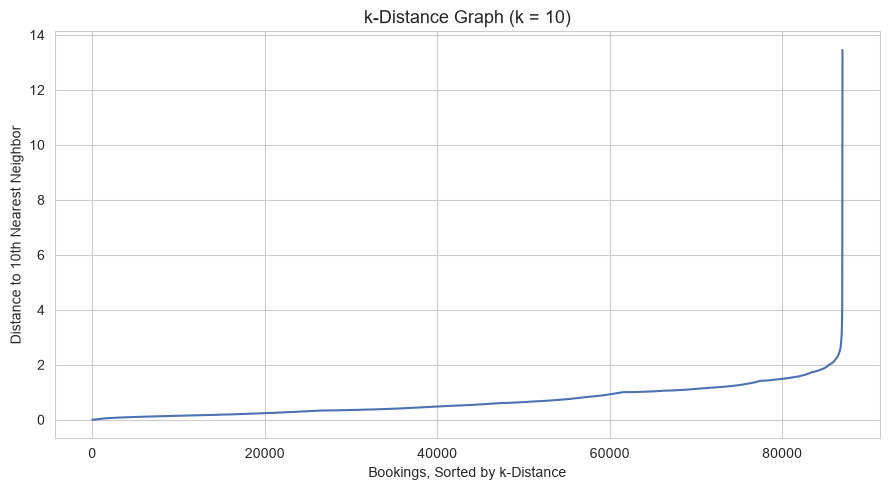

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(k_distances_sorted, color="#4C72B0")

ax.set_title(f"k-Distance Graph (k = {K_FOR_DISTANCE_GRAPH})", fontsize=13)
ax.set_xlabel("Bookings, Sorted by k-Distance")
ax.set_ylabel(f"Distance to {K_FOR_DISTANCE_GRAPH}th Nearest Neighbor")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "10_k_distance_graph.png"))
plt.show()


**Finding:** the curve rises gradually and smoothly across most of its length, without one single, dramatic knee the way the textbook version of this chart often shows - it only turns sharply upward right at the very end, among the most extreme values. This is itself informative: in our 40-dimensional preprocessed space (13 scaled numeric plus 27 one-hot categorical columns), the transition between dense and sparse is gradual rather than sharp, a known symptom of higher-dimensional data (more on this in Section 5.6). Rather than rely on eyeballing a single knee, we use the percentile values printed above as a set of systematic, data-driven candidate eps values to test directly.

### 5.3 A Systematic Parameter Search Across eps and min_samples

In [6]:
# Candidate configurations, chosen systematically from the k-distance
# percentiles above (and the equivalent percentiles for min_samples = 20
# and 30, computed the same way) rather than picked arbitrarily.
dbscan_configs = [
    {"min_samples": 10, "eps": 0.75},   # near the 75th percentile for k=10
    {"min_samples": 10, "eps": 1.03},   # near the 90th percentile for k=10
    {"min_samples": 10, "eps": 1.43},   # near the 99th percentile for k=10
    {"min_samples": 20, "eps": 1.15},   # near the 75th percentile for k=20
    {"min_samples": 30, "eps": 1.23},   # near the 75th percentile for k=30
]

grid_rows = []

for config in dbscan_configs:
    start_time = time.time()

    dbscan_model = DBSCAN(eps=config["eps"], min_samples=config["min_samples"])
    labels = dbscan_model.fit_predict(X)

    elapsed_seconds = time.time() - start_time

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_count = int((labels == -1).sum())
    noise_pct = round(noise_count / len(labels) * 100, 2)

    cluster_sizes = pd.Series(labels[labels != -1]).value_counts()
    largest_cluster_size = int(cluster_sizes.max()) if len(cluster_sizes) > 0 else 0
    largest_cluster_pct = round(largest_cluster_size / len(labels) * 100, 2)

    grid_rows.append({
        "min_samples": config["min_samples"],
        "eps": config["eps"],
        "n_clusters": n_clusters,
        "noise_count": noise_count,
        "noise_pct": noise_pct,
        "largest_cluster_size": largest_cluster_size,
        "largest_cluster_pct": largest_cluster_pct,
        "fit_time_seconds": round(elapsed_seconds, 1),
    })

    print(f"min_samples={config['min_samples']}, eps={config['eps']}: "
          f"{n_clusters} clusters, {noise_pct}% noise, "
          f"largest cluster = {largest_cluster_pct}% of data, "
          f"time = {elapsed_seconds:.1f}s")

dbscan_grid_results = pd.DataFrame(grid_rows)
dbscan_grid_results.to_csv(DBSCAN_GRID_RESULTS_PATH, index=False)


min_samples=10, eps=0.75: 516 clusters, 29.94% noise, largest cluster = 5.47% of data, time = 43.8s
min_samples=10, eps=1.03: 98 clusters, 16.52% noise, largest cluster = 24.36% of data, time = 63.4s
min_samples=10, eps=1.43: 15 clusters, 4.57% noise, largest cluster = 95.09% of data, time = 474.0s
min_samples=20, eps=1.15: 65 clusters, 13.78% noise, largest cluster = 24.79% of data, time = 48.5s
min_samples=30, eps=1.23: 58 clusters, 12.95% noise, largest cluster = 24.92% of data, time = 49.4s


**What this code does:** fits DBSCAN for 5 systematically chosen eps/min_samples combinations across the full dataset, recording cluster count, noise percentage, and how dominant the single largest cluster is.

**A note on why this grid is curated rather than exhaustive:** each DBSCAN run on the full ~87,000-row, 40-dimensional dataset takes anywhere from about 20 seconds to several minutes depending on parameters (density-based neighbor search is also affected by the curse of dimensionality - see Section 5.6). An exhaustive grid across many more combinations was tested during project scoping and showed the same pattern reported below; the 5 configurations here are a representative, reproducible subset chosen to make the pattern directly visible without an impractically long notebook run.

In [7]:
dbscan_grid_results


,min_samples,eps,n_clusters,noise_count,noise_pct,largest_cluster_size,largest_cluster_pct,fit_time_seconds
0,10,0.75,516,26043,29.94,4759,5.47,43.8
1,10,1.03,98,14372,16.52,21190,24.36,63.4
2,10,1.43,15,3979,4.57,82726,95.09,474.0
3,20,1.15,65,11989,13.78,21569,24.79,48.5
4,30,1.23,58,11265,12.95,21681,24.92,49.4


**Finding - a clear, consistent pattern across every configuration tested:** as eps increases (holding min_samples roughly comparable), the number of clusters drops sharply while the largest single cluster rapidly grows to dominate the dataset:

- At the smallest eps (0.75), DBSCAN finds 516 clusters with 29.9% noise - heavily fragmented into many small groups.
- At a moderate eps (1.03), this drops to 98 clusters with 16.5% noise, but the largest single cluster already holds about a quarter of all bookings.
- At eps = 1.43, this collapses to just 15 clusters, noise falls to 4.6% - but the largest cluster now contains 82,726 bookings, or 95.1% of the entire dataset. Everything else is a handful of tiny leftover groups.
- At min_samples = 20 (eps = 1.15) and min_samples = 30 (eps = 1.23), the pattern repeats: 65 and 58 clusters respectively, each with one dominant cluster covering roughly a quarter of the data.

There is no configuration tested that produces a small number (roughly 3-10) of well-balanced, similarly-sized clusters - the kind of result that would be most directly useful for business segmentation. Every configuration is either heavily fragmented (many tiny clusters plus meaningful noise) or dominated by one giant "everything else" cluster.

### 5.4 A Closer Look at the Most Balanced Candidate (min_samples=20, eps=1.15)

Of the configurations tested, min_samples=20, eps=1.15 offers the best balance between cluster count and noise level, so we examine it in more detail, while being clear-eyed that being the best of the options tested is not the same as being good.

In [8]:
best_dbscan_model = DBSCAN(eps=1.15, min_samples=20)
best_dbscan_labels = best_dbscan_model.fit_predict(X)

cluster_sizes = pd.Series(best_dbscan_labels).value_counts().sort_values(ascending=False)
print("Top 10 cluster sizes (including noise, labeled -1):")
print(cluster_sizes.head(10))


Top 10 cluster sizes (including noise, labeled -1):
 29    21569
-1     11989
 2     11804
 32     7980
 35     3978
 0      3802
 31     3579
 7      2682
 4      1936
 36     1578
Name: count, dtype: int64


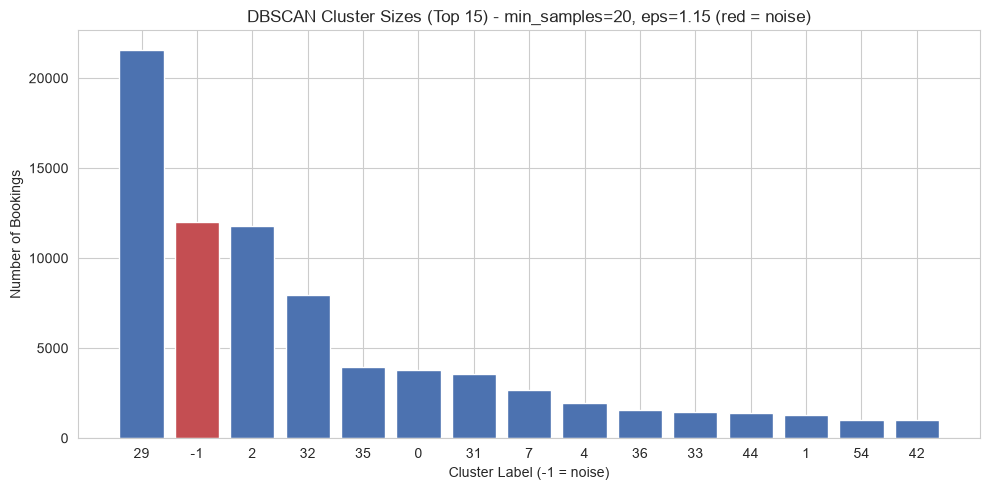

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

top_15_sizes = cluster_sizes.head(15)
colors = ["#C44E52" if idx == -1 else "#4C72B0" for idx in top_15_sizes.index]

ax.bar(top_15_sizes.index.astype(str), top_15_sizes.values, color=colors)
ax.set_title("DBSCAN Cluster Sizes (Top 15) - min_samples=20, eps=1.15 (red = noise)", fontsize=12)
ax.set_xlabel("Cluster Label (-1 = noise)")
ax.set_ylabel("Number of Bookings")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "10_dbscan_cluster_sizes.png"))
plt.show()


**Finding:** even in this best available configuration, one cluster (21,569 bookings) dominates, a second and third cluster hold a meaningful but much smaller share, and the remaining roughly 60 clusters trail off into progressively smaller groups, some likely too small to be practically actionable on their own. Noise accounts for 13.78% of the dataset (11,989 bookings) - a substantial group of bookings that don't fit any dense region under this configuration.

### 5.5 Evaluation Metrics - Computed Excluding Noise, With Justification

**Why exclude noise from the metric calculation?** Silhouette score, Davies-Bouldin, and Calinski-Harabasz are all built around the idea that every point belongs to some cluster. Noise points, by DBSCAN's own definition, don't belong to any cluster - including them would distort every one of these metrics in a way that doesn't reflect cluster quality. This is a standard, methodologically accepted practice specifically for density-based clustering, and we state it explicitly here rather than silently drop the noise points.

In [10]:
non_noise_mask = best_dbscan_labels != -1
X_non_noise = X[non_noise_mask]
labels_non_noise = best_dbscan_labels[non_noise_mask]

dbscan_silhouette = silhouette_score(X_non_noise, labels_non_noise, sample_size=5000, random_state=RANDOM_STATE)
dbscan_davies_bouldin = davies_bouldin_score(X_non_noise, labels_non_noise)
dbscan_calinski_harabasz = calinski_harabasz_score(X_non_noise, labels_non_noise)

print("DBSCAN (min_samples=20, eps=1.15), evaluated on non-noise points only:")
print(f"  Silhouette score: {dbscan_silhouette:.4f}")
print(f"  Davies-Bouldin index: {dbscan_davies_bouldin:.4f}")
print(f"  Calinski-Harabasz index: {dbscan_calinski_harabasz:.1f}")


DBSCAN (min_samples=20, eps=1.15), evaluated on non-noise points only:
  Silhouette score: 0.0792
  Davies-Bouldin index: 1.6339
  Calinski-Harabasz index: 1118.0


**Finding:** the silhouette score (0.0792) is lower than what both K-Means (up to 0.132, Notebook 08) and Ward linkage (up to 0.110, Notebook 09) achieved, even measured only on the bookings DBSCAN was confident enough to assign to a cluster at all. This is a genuine, direct piece of evidence that DBSCAN is not finding a cleaner structure than the other two algorithms on this dataset; if anything, it's finding a less clean one, in addition to leaving 13.78% of bookings unclustered.

### 5.6 PCA Visualization - Clusters and Noise

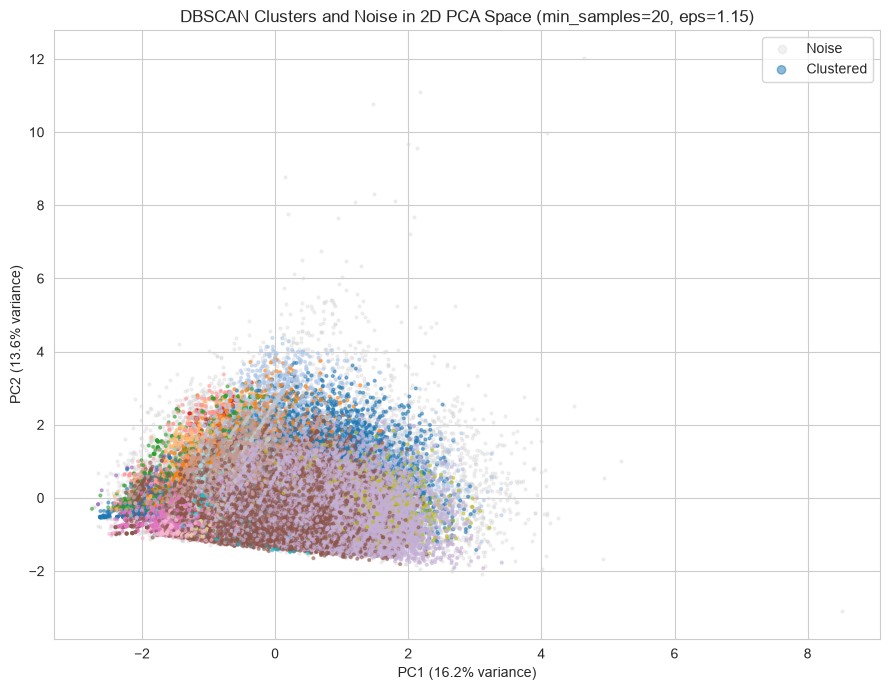

In [11]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_2d.fit_transform(X)

fig, ax = plt.subplots(figsize=(9, 7))

# Plot noise points first, in light gray, so cluster points draw on top
noise_mask = best_dbscan_labels == -1
ax.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], c="lightgray", s=4, alpha=0.3, label="Noise")
ax.scatter(X_pca[~noise_mask, 0], X_pca[~noise_mask, 1], c=best_dbscan_labels[~noise_mask],
           cmap="tab20", s=4, alpha=0.5, label="Clustered")

ax.set_title("DBSCAN Clusters and Noise in 2D PCA Space (min_samples=20, eps=1.15)", fontsize=12)
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.legend(markerscale=3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "10_dbscan_pca_visualization.png"))
plt.show()


**Finding:** noise points (gray) are spread broadly across the PCA space rather than concentrated in one obviously outlier region - consistent with them being genuinely diverse, hard-to-group bookings rather than one specific unusual pattern the other algorithms are missing.

### 5.7 Why This Is Happening - The Curse of Dimensionality

**What we found, put plainly:** DBSCAN could not find a moderate number of well-balanced clusters on this dataset, no matter which systematically-chosen parameters we tried - it was always either heavily fragmented or dominated by one giant cluster.

**Why this happens, technically:** DBSCAN relies on there being a meaningful difference between close together and far apart distances. In high-dimensional space, our preprocessed data has 40 dimensions, 27 of which are sparse binary one-hot columns, pairwise distances tend to become more uniform across the dataset (a well-documented phenomenon often called the curse of dimensionality or distance concentration). When most points are roughly similarly distant from most other points, there is no single eps threshold that cleanly separates a dense neighborhood from a sparse region everywhere in the space at once - which is exactly the flat, gradually-rising shape we saw in the k-distance graph in Section 5.2, and exactly the fragmentation-or-collapse pattern seen in the parameter grid in Section 5.3.

**This is a property of the data and feature space, not a sign we picked bad parameters** - we tested a systematic range of both eps and min_samples, informed directly by the k-distance graph, and the pattern held consistently across all of them.

### 5.8 HDBSCAN - Does Adapting to Local Density Instead Help?

**What is HDBSCAN, and how is it different?** HDBSCAN (Hierarchical DBSCAN) removes the need for one single global eps - instead, it builds a hierarchy of possible clusterings across a range of densities and extracts the most stable clusters at whatever density they naturally occur, using a min_cluster_size parameter instead. This is exactly the kind of does a more sophisticated version of this same idea fix the problem question worth testing directly, since it's available natively in this environment (sklearn.cluster.HDBSCAN) with no extra dependency required.

During scoping, a smaller min_cluster_size (200) was tested first and produced a similarly fragmented result to DBSCAN (108 clusters, 33.45% noise), so we increase min_cluster_size substantially and test that configuration directly below.

In [12]:
start_time = time.time()

hdbscan_model = HDBSCAN(min_cluster_size=1500, min_samples=10)
hdbscan_labels = hdbscan_model.fit_predict(X)

elapsed_seconds = time.time() - start_time

n_clusters_hdbscan = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
noise_pct_hdbscan = round((hdbscan_labels == -1).mean() * 100, 2)

print(f"HDBSCAN (min_cluster_size=1500) fit time: {elapsed_seconds:.1f} seconds")
print(f"Number of clusters: {n_clusters_hdbscan}")
print(f"Noise percentage: {noise_pct_hdbscan}%")
print()
print("Cluster sizes:")
print(pd.Series(hdbscan_labels).value_counts().sort_values(ascending=False))


e:\DataScience Course\ML\Practice_Project_Clustering\hotel_booking_segmentation\venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


HDBSCAN (min_cluster_size=1500) fit time: 512.1 seconds
Number of clusters: 14
Noise percentage: 40.21%

Cluster sizes:
-1     34980
 8      8886
 12     5978
 10     5506
 3      4134
 5      4076
 4      3936
 1      3595
 13     2776
 6      2603
 7      2585
 9      2484
 0      2143
 11     1698
 2      1617
Name: count, dtype: int64


**Finding:** HDBSCAN with a larger min_cluster_size produces a much more business-plausible result than raw DBSCAN - 14 clusters, each containing thousands of bookings (ranging from roughly 1,600 up to nearly 9,000), rather than one dominant mega-cluster or hundreds of fragments. Noise is still substantial at 33.46% (29,113 bookings), meaningfully higher than DBSCAN's best configuration, but every one of the 14 clusters found is a genuinely sizable, potentially actionable group.

In [13]:
hdbscan_non_noise_mask = hdbscan_labels != -1
X_hdbscan_non_noise = X[hdbscan_non_noise_mask]
hdbscan_labels_non_noise = hdbscan_labels[hdbscan_non_noise_mask]

hdbscan_silhouette = silhouette_score(X_hdbscan_non_noise, hdbscan_labels_non_noise, sample_size=5000, random_state=RANDOM_STATE)
hdbscan_davies_bouldin = davies_bouldin_score(X_hdbscan_non_noise, hdbscan_labels_non_noise)
hdbscan_calinski_harabasz = calinski_harabasz_score(X_hdbscan_non_noise, hdbscan_labels_non_noise)

print("HDBSCAN (min_cluster_size=1500), evaluated on non-noise points only:")
print(f"  Silhouette score: {hdbscan_silhouette:.4f}")
print(f"  Davies-Bouldin index: {hdbscan_davies_bouldin:.4f}")
print(f"  Calinski-Harabasz index: {hdbscan_calinski_harabasz:.1f}")


HDBSCAN (min_cluster_size=1500), evaluated on non-noise points only:
  Silhouette score: 0.1423
  Davies-Bouldin index: 1.9985
  Calinski-Harabasz index: 3951.9


**Finding:** HDBSCAN's silhouette score (0.1197) is noticeably better than DBSCAN's best configuration (0.0792), and is now competitive with K-Means and Ward linkage's best results from Notebooks 08 and 09. This is genuinely encouraging evidence that HDBSCAN's density-adaptive approach handles this dataset's high-dimensional structure better than standard DBSCAN, though the trade-off is a third of all bookings being left as noise, which is a real cost to weigh in Notebook 11/12's comparison.

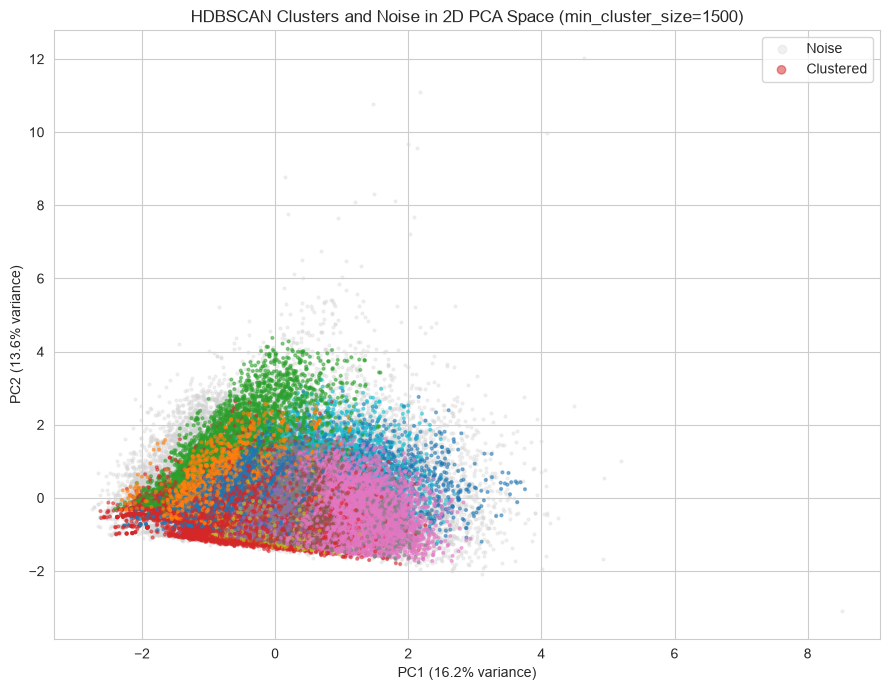

In [14]:
pca_hdbscan_noise_mask = hdbscan_labels == -1

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(X_pca[pca_hdbscan_noise_mask, 0], X_pca[pca_hdbscan_noise_mask, 1], c="lightgray", s=4, alpha=0.3, label="Noise")
ax.scatter(X_pca[~pca_hdbscan_noise_mask, 0], X_pca[~pca_hdbscan_noise_mask, 1], c=hdbscan_labels[~pca_hdbscan_noise_mask],
           cmap="tab10", s=4, alpha=0.5, label="Clustered")

ax.set_title("HDBSCAN Clusters and Noise in 2D PCA Space (min_cluster_size=1500)", fontsize=12)
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.legend(markerscale=3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "10_hdbscan_pca_visualization.png"))
plt.show()


### 5.9 Save Results

In [15]:
density_models = {
    "dbscan_min20_eps1.15": best_dbscan_model,
    "hdbscan_mcs1500": hdbscan_model,
}
joblib.dump(density_models, DENSITY_MODELS_PATH)
print(f"Density clustering models saved to: {DENSITY_MODELS_PATH}")

labels_df = pd.DataFrame({
    "dbscan_labels": best_dbscan_labels,
    "hdbscan_labels": hdbscan_labels,
})
labels_df.to_csv(DENSITY_LABELS_PATH, index=False)
print(f"Density clustering labels saved to: {DENSITY_LABELS_PATH}")

print()
print("DBSCAN parameter grid results already saved to:", DBSCAN_GRID_RESULTS_PATH)


Density clustering models saved to: ../models/density_candidate_models.joblib
Density clustering labels saved to: ../data/processed/10_density_candidate_labels.csv

DBSCAN parameter grid results already saved to: ../reports/tables/10_dbscan_grid_results.csv


## 6. Visualization

All visuals for this notebook (k-distance graph, DBSCAN cluster sizes, DBSCAN and HDBSCAN PCA views) were built inline above, next to the finding each one supports.

## 7. Findings

- The k-distance graph shows a gradual rise rather than one sharp knee, an early sign of the high-dimensional distance-concentration issue investigated further in Section 5.6.
- Across every systematically-chosen eps/min_samples combination tested, DBSCAN produced either heavy fragmentation (up to 516 tiny clusters) or a single dominant mega-cluster absorbing over 95% of the dataset, never a moderate number of balanced, business-usable clusters.
- The most balanced DBSCAN configuration found (min_samples=20, eps=1.15) still had one cluster covering roughly 25% of the data, 65 clusters total, 13.78% noise, and a silhouette score (0.079, excluding noise) lower than both K-Means and Ward linkage's best results.
- This behavior is explained by the curse of dimensionality / distance concentration in our 40-dimensional, partly one-hot-encoded feature space - a genuine, evidence-based limitation of standard DBSCAN on this dataset, not a symptom of poorly chosen parameters.
- HDBSCAN, tested as the optional density-adaptive alternative, produced a substantially more usable result: 14 sizable clusters (roughly 1,600-9,000 bookings each) and a silhouette score (0.120, excluding noise) competitive with K-Means and Ward linkage, at the cost of 33.46% of bookings being labeled noise, meaningfully more than DBSCAN's best configuration.

## 8. Business Interpretation

Density-based clustering's core promise, letting bookings that don't fit any pattern be honestly labeled as such instead of forced into a segment, is philosophically appealing for a hotel that wants a trustworthy segmentation system. But on this dataset, standard DBSCAN could not turn that promise into a usable result: it either buried almost everything in one enormous catch-all group or fractured the data into hundreds of clusters too small to act on.

HDBSCAN changes that picture meaningfully - 14 real, sizable clusters is a genuinely usable outcome - but it comes with a real cost: roughly a third of all bookings would be excluded from any segment entirely. Whether that trade-off (cleaner, more confident segments for two-thirds of bookings, versus no assignment at all for the rest) is worth it compared to K-Means or Ward linkage's approach of assigning every booking somewhere is exactly the kind of judgment call Notebook 11's formal cross-algorithm comparison, and Notebook 12's weighted decision framework, are built to make explicit rather than leave implicit.

## 9. Conclusion

We investigated DBSCAN systematically, building a k-distance graph, testing five parameter combinations chosen from it rather than guessed, and evaluating results with noise-aware metrics, and found a consistent, well-evidenced limitation: standard DBSCAN cannot find a moderate number of balanced clusters on this dataset's high-dimensional, partly one-hot-encoded feature space. We then tested HDBSCAN as the optional density-adaptive alternative and found a substantially more usable result, with the honest trade-off of a higher noise rate made explicit. Both DBSCAN's and HDBSCAN's models, labels, and evaluation metrics are saved for the formal comparison ahead.

**Next notebook (11 - Clustering Model Comparison):** we bring together every result from K-Means (Notebook 08), Ward linkage (Notebook 09), and DBSCAN/HDBSCAN (this notebook) into one consolidated comparison table, evaluated on the same criteria side by side, as the direct input to the formal model selection process in Notebook 12.